#*Kernel Canvas*


O Kernel Canvas é um método de normalização capaz de lidar com dados que não possuem tamanho fixo. Sua concepção foi motivada para classificação de dados de séries temporais e/ou de ambientes dinâmicos, que, conforme se faz a necessidade, requerem registrar uma "janela de contexto" aumentando com tendência exponencial o tamanho dos dados. Nesse panorama, essa ferramenta também reduzir a dimensionalização dos dados mantendo a relação da janela.

In [ ]:
#@title Install dependencies [RUN ME]
!pip install --upgrade setuptools
!pip install ipykernel
!pip install pybind11
!pip install git+https://github.com/IAZero/wisardpkg.git@develop
!pip install numpy
!pip install matplotlib
!pip install scikit-learn
!pip install ipywidgets
!pip install numba

  Cloning https://github.com/IAZero/wisardpkg.git (to revision develop) to /tmp/pip-req-build-bsob7cyu
  Running command git clone --filter=blob:none --quiet https://github.com/IAZero/wisardpkg.git /tmp/pip-req-build-bsob7cyu
  Running command git checkout -b develop --track origin/develop
  Switched to a new branch 'develop'
  Branch 'develop' set up to track remote branch 'develop' from 'origin'.
  Resolved https://github.com/IAZero/wisardpkg.git to commit c51b395c0e85ae007bb7f8699515a3136356ef65
  Preparing metadata (setup.py) ... done
  Created wheel for wisardpkg: filename=wisardpkg-2.0.0a7-cp312-cp312-linux_x86_64.whl size=5856619 sha256=12ceccb9fc5553faac526ed8eea76d88172da8dd82573c8e1ef4b0653ec29d6f
  Stored in directory: /tmp/pip-ephem-wheel-cache-earhis6i/wheels/50/3e/03/dd5396e10cc00163868ada49e05e6464110639bb276c6ecc7a
Successfully built wisardpkg


## Implementação

Quando instâncidado, é necessário informar a dimensão dos dados (*dim*) a serem normalizados e o número de *Kernels* (*numberOfKernels*) que deseja se criar. O mínimo aceito é 1 para todos esses valores.

Quanto aos parâmetros opcionais:
- ***bitsBykernel*** : como o nome indica, se refere a quantidade de bits que representará cada *kernel*. Mínimo aceito é 1 e o padrão quando não informado é 3.

- ***activationDegree*** : se refere a proporção de *kernels* a serem ativados.

- ***useDirection*** : quando ativado, considera a *janela de contexto* dos dados. Guarda, para cada kernel, o valor do kernel que foi acessado antes e o depois.



```

kc = KernelCanvas(
    dimension,               # required; type [int]
    numberOfKernels,         # required; type [int]
    bitsBykernel = 3,        # optional; type [int]
    activationDegree = 0.07, # optional; type [float]
    useDirection = False     # optional; type [boolean]
)
```

In [ ]:
import wisardpkg as wp
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
from random import random

## Criando objeto para dados de 2 dimensões, 16 kernels e 1 bits pra cada kernel
kc = wp.KernelCanvas(3, 16, bitsByKernel = 1, activationDegree=0.07, useDirection=False)

Dando uma olhada nos dados

In [ ]:

### exemplo
sequenceData = []
for i in range(10):
    point = [0.0,0.0] # duas dimensões
    point[0] = 10*random()
    point[1] = 10*random()

    sequenceData.append(point)

sequenceData

[[4.74334169546221, 0.12102646008760987],
 [0.21592558855972221, 1.8767278705864554],
 [3.7043897898037805, 3.7197994953289393],
 [3.0088059161746594, 0.00972107845864878],
 [5.555441289159027, 8.15598536987312],
 [9.036339615949428, 5.448017836383987],
 [4.519942199824273, 6.777170695577736],
 [7.138714773601543, 6.08133177430354],
 [1.2652832661929025, 8.359847955637106],
 [0.8627058422375711, 8.810224450964792]]

###Fazendo transformação - Método *transform()*

O método recebe uma **lista** de pontos de valores reais e retorna uma lista de novos inputs binários mapeados pelos kernels. O tamanho será igual a `numberOfKernels * bitsBykernel`.

In [ ]:
sequence_ = []
sequenceData_ = []

for i in range(10000):
  sequenceData_ = []
  for j in range(10):
    point = [0.0,0.0]
    point[0] = 100*random()
    point[1] = 100*random()
    sequenceData_.append(point)

  sequence_.append(sequenceData_)

In [ ]:
sequence_[0]

[[35.81167362201988, 72.25200382528666],
 [57.126008855619425, 66.3933312942631],
 [25.195204484631397, 56.143798461248],
 [35.48565948938294, 35.62711904810215],
 [35.20270975509371, 64.19919834915633],
 [84.81239678604835, 52.86229249234437],
 [13.044260561626675, 30.849061126807943],
 [94.29255672432842, 3.142703519972434],
 [76.788914742687, 49.58335877236203],
 [22.985921759064954, 30.62652016478139]]

In [ ]:
out_ = [kc.transform(x) for x in sequence_]

for i in range(100):
  print(out_[i],'\n')

[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0] 

[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0] 

[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 

[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0] 

[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0] 

[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1] 

[1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1, 1, 1, 0, 0, 0, 1, 1, 1, 

-----

In [ ]:
#@title Exemplo PenDigits
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd
from urllib.request import urlopen

# URL oficial do dataset no UCI
# url_train = "https://archive.ics.uci.edu/ml/machine-learning-databases/pendigits/pendigits.tra"
# url_test = "https://archive.ics.uci.edu/ml/machine-learning-databases/pendigits/pendigits.tes"
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/pendigits/pendigits.tra -O pendigits_train.csv
!wget -q https://archive.ics.uci.edu/ml/machine-learning-databases/pendigits/pendigits.tes -O pendigits_test.csv

In [ ]:


# Ler CSVs (sem cabeçalho, separador vírgula)
col_names = [f"f{i}" for i in range(16)] + ["target"]
# train_df = pd.read_csv(urlopen(url_train), header=None, names=col_names)
# test_df = pd.read_csv(urlopen(url_test), header=None, names=col_names)
train_df = pd.read_csv("pendigits_train.csv", header=None, names=col_names)
test_df = pd.read_csv("pendigits_test.csv", header=None, names=col_names)


# Juntar train e test
df = pd.concat([train_df, test_df], ignore_index=True)

X = df.iloc[:, :-1].values
y = df.iloc[:, -1].values


X = X.astype(float)
y = y.astype(str)



print(f"Forma dos dados: {X.shape}")
print(f"Forma dos labels: {y.shape}")


Forma dos dados: (10992, 16)
Forma dos labels: (10992,)


In [ ]:
X_ = [ ]
for i in range(len(X)):
  points = [ ]
  for j in range(0, len(X[0]), 2):
    point = [X[i, j], X[i, j+1]]
    points.append(point)
  X_.append(points)

In [ ]:
X_[0]

[[np.float64(47.0), np.float64(100.0)],
 [np.float64(27.0), np.float64(81.0)],
 [np.float64(57.0), np.float64(37.0)],
 [np.float64(26.0), np.float64(0.0)],
 [np.float64(0.0), np.float64(23.0)],
 [np.float64(56.0), np.float64(53.0)],
 [np.float64(100.0), np.float64(90.0)],
 [np.float64(40.0), np.float64(98.0)]]

In [ ]:
def show_digits(digit, label):
  x_coords = [point[0] for point in digit]
  y_coords = [point[1] for point in digit]
  plt.figure(figsize=(4,4))
  plt.title(f"Label: {label}")
  plt.plot(x_coords, y_coords, 'ro-')  # Plot the points
  plt.axis('equal')
  plt.show()

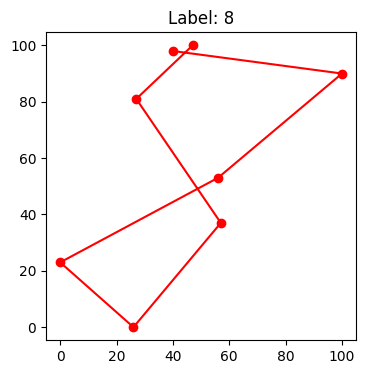

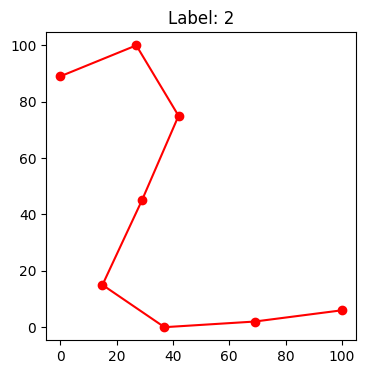

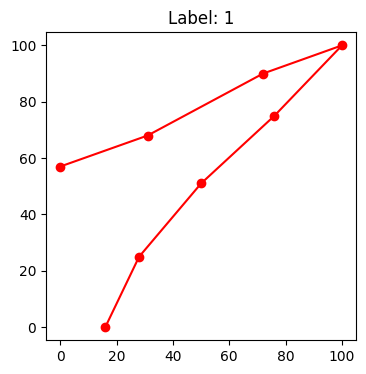

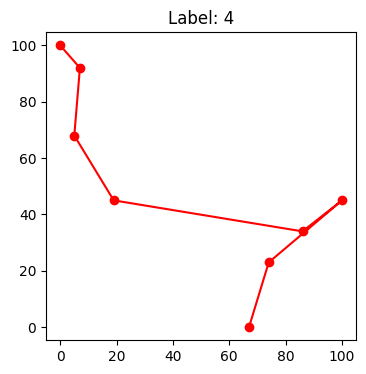

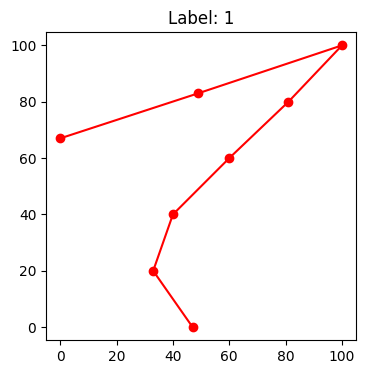

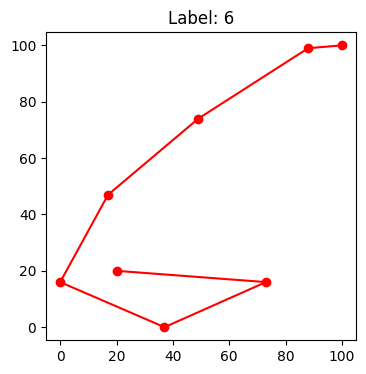

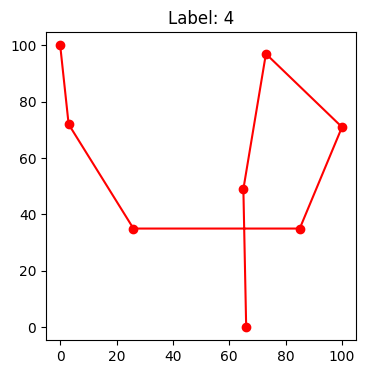

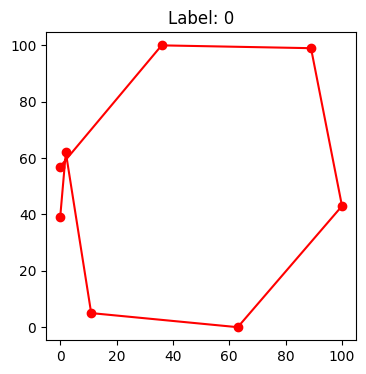

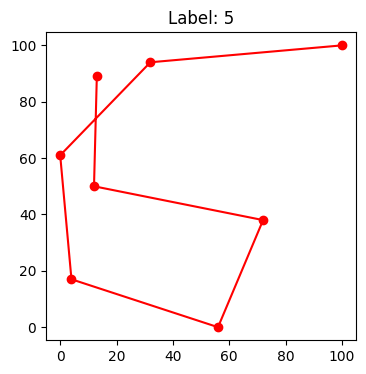

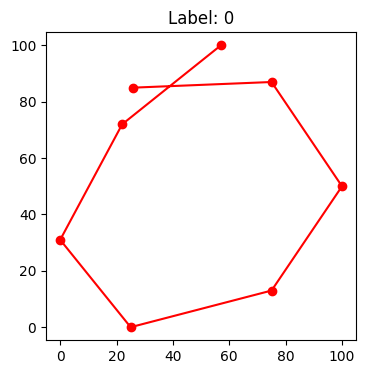

In [ ]:
n = 2
for i in range(10):
  show_digits(X_[i], y[i])


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X_, y, test_size=0.2, random_state=42)

In [ ]:
len(X_test)

2199

In [ ]:
tem_nulos = np.isnan(X_test).any()

print(tem_nulos)

False


In [ ]:
lengths = {len(x) for x in X_train}
print(lengths)


{8}


In [ ]:
shapes = {np.shape(x) for x in X_train}
print(shapes)


{(8, 2)}


In [ ]:
kernel_ = wp.KernelCanvas(2, 254, bitsByKernel = 1, activationDegree=0.1, useDirection=True)

In [ ]:
test = kernel_.transform(X_train[0])

In [ ]:
train_points = [kernel_.transform(x) for x in X_train]



In [ ]:
test_points = [kernel_.transform(x) for x in X_test]

In [ ]:
model = wp.Wisard(32)

In [ ]:
train_ds = wp.DataSet(train_points, y_train.tolist())
test_ds = wp.DataSet(test_points, y_test.tolist())

In [ ]:
model.train(train_ds)

In [ ]:
pred = model.classify(test_ds)

In [ ]:
def accuracy(y_pred, y_target):
  return np.where(y_pred == y_target, 1, 0).sum()/len(y_target)

In [ ]:
accuracy(pred, y_test)

np.float64(0.931787175989086)